# Diffusion equation:
This is the diffusion equation: $$ \frac{\partial z}{\partial t} = D\frac{\partial^2 z}{\partial x^2} $$ and $$ z^{t+1}_x = z^t_x + {D \Delta t \over \Delta x^2} (z^t_{x+1} - 2z^t_x + z^t_{x-1}) $$Assuming constant diffusivity, a regular grid, and a step function for the initial profile. Here, $z$ is elevation, $t$ is time, $x$ is the spatial dimension and $D$ is a transport rate coefficient, sometimes called hillslope diffusivity.

This is the forward in time centered-in-space discretization scheme.

In [2]:
import os
import sys
import tomllib

import numpy as np
import matplotlib.pyplot as plt

In [3]:
def calculate_stable_time_step(dx, diffusivity):
    return 0.5 * dx**2 / diffusivity


def step_like(x, step_at=0):
    y = np.empty_like(x, dtype=float)

    y[:step_at] = 0.0
    y[step_at] = 0.5
    y[step_at + 1 :] = 1.0

    return y


def boxcar_like(x, step_at=0):
    return step_like(x, step_at=step_at) - step_like(x, step_at=len(x) - step_at - 1)


def new_profile(x, form="step"):
    match form:
        case "step":
            return step_like(x, step_at=len(x) // 2)
        case "boxcar":
            return boxcar_like(x, step_at=len(x) // 4)
        case "bowl":
            return 1.0 - boxcar_like(x, step_at=len(x) // 4)
        case "wedding":
            return boxcar_like(x, step_at=len(x) // 8) + boxcar_like(
                x, step_at=3 * len(x) // 8
            )
        case _:
            raise ValueError(f"unknown profile type ({form!r})")


def plot_profile(x, elevation, color="r"):
    plt.figure()
    plt.plot(x, elevation, color)
    plt.xlabel("x")
    plt.ylabel("z")
    plt.title("Hillslope profile")


def calculate_second_derivative(y, dx=1.0):
    d2y_dx2 = np.empty_like(y)

    d2y_dx2[1:-1] = (y[:-2] - 2 * y[1:-1] + y[2:]) / dx**2
    d2y_dx2[0] = 0.0
    d2y_dx2[-1] = 0.0

    return d2y_dx2


def diffuse_until(y_initial, stop_time, dx=1.0, diffusivity=1.0):
    stable_dt = 0.9 * calculate_stable_time_step(dx, diffusivity)

    y = y_initial.copy()

    time_remaining = stop_time
    while time_remaining > 0.0:
        dt = min(time_remaining, stable_dt)

        y += diffusivity * dt * calculate_second_derivative(y, dx=dx)

        time_remaining -= dt

    return y


def run_diffusion_model(
    diffusivity=100.0, width=100.0, stop_time=1.0, n_points=81, profile="step"
):
    x, dx = np.linspace(0, width, num=n_points, retstep=True)
    initial_elevation = new_profile(x, form=profile)

    elevation = diffuse_until(
        initial_elevation, stop_time, dx=dx, diffusivity=diffusivity
    )

    plot_profile(x, initial_elevation, "g")
    plot_profile(x, elevation, "r")
    plt.show()

    return elevation


def load_params_from_path(filepath):
    with open(filepath, "rb") as stream:
        params = tomllib.load(stream)
    return params

In [14]:
%pip install mpl_ascii

Defaulting to user installation because normal site-packages is not writeable
  Using cached mpl_ascii-1.0.1-py3-none-any.whl.metadata (4.7 kB)
Using cached mpl_ascii-1.0.1-py3-none-any.whl (35 kB)
Note: you may need to restart the kernel to use updated packages.


In [4]:
if __name__ == "__main__":
    import matplotlib as mpl
    import mpl_ascii

    mpl_ascii.AXES_WIDTH = 70
    mpl_ascii.AXES_HEIGHT = 15

    mpl.use("module://mpl_ascii")

    filepath = "diffusion.toml"

    if os.path.isfile(filepath):
        params = load_params_from_path(filepath)
    else:
        params = {}
    elevation = run_diffusion_model(**params)

    np.savetxt(sys.stdout, elevation, fmt="%.6f")

Hillslope profile                             
                                                                            
         ┌──────────────────────────────────────────────────────────┐       
     1.0 ┤                             !!!!!!!!!!!!!!!!!!!!!!!!!!!  │       
         │                             !                            │       
         │                             !                            │       
         │                             !                            │       
     0.8 ┤                             !                            │       
         │                            !                             │       
         │                            !                             │       
         │                            !                             │       
     0.6 ┤                            !                             │       
         │                            !                             │       
    z    │                            !                             │       
         │                            !                             │       
     0.4 ┤                            !                             │       
         │                            !                             │       
         │                            !                             │       
         │                            !                             │       
     0.2 ┤                            !                             │       
         │                            !                             │       
         │                            !                             │       
         │                            !                             │       
         │                            !                             │       
     0.0 ┤  !!!!!!!!!!!!!!!!!!!!!!!!!!!                             │       
         └──┬──────────┬─────────┬──────────┬─────────┬──────────┬──┘       
            0         20        40         60        80         100         
                                                                            
                                      x

Hillslope profile                             
                                                                            
         ┌──────────────────────────────────────────────────────────┐       
     1.0 ┤                                          !!!!!!!!!!!!!!  │       
         │                                       !!!                │       
         │                                     !!                   │       
         │                                    !                     │       
     0.8 ┤                                  !!                      │       
         │                                 !!                       │       
         │                                !                         │       
         │                               !!                         │       
     0.6 ┤                              !                           │       
         │                             !!                           │       
    z    │                            !                             │       
         │                            !                             │       
     0.4 ┤                          !!                              │       
         │                          !                               │       
         │                        !!                                │       
         │                        !                                 │       
     0.2 ┤                      !!                                  │       
         │                     !!                                   │       
         │                   !!!                                    │       
         │                 !!!                                      │       
         │           !!!!!!                                         │       
     0.0 ┤  !!!!!!!!!                                               │       
         └──┬──────────┬─────────┬──────────┬─────────┬──────────┬──┘       
            0         20        40         60        80         100         
                                                                            
                                      x

0.000000
0.000133
0.000278
0.000449
0.000659
0.000927
0.001271
0.001714
0.002285
0.003018
0.003951
0.005131
0.006612
0.008457
0.010737
0.013532
0.016931
0.021032
0.025941
0.031770
0.038636
0.046662
0.055970
0.066677
0.078900
0.092743
0.108299
0.125643
0.144829
0.165890
0.188827
0.213615
0.240196
0.268478
0.298337
0.329617
0.362133
0.395672
0.430001
0.464865
0.500000
0.535135
0.569999
0.604328
0.637867
0.670383
0.701663
0.731522
0.759804
0.786385
0.811173
0.834110
0.855171
0.874357
0.891701
0.907257
0.921100
0.933323
0.944030
0.953338
0.961364
0.968230
0.974059
0.978968
0.983069
0.986468
0.989263
0.991543
0.993388
0.994869
0.996049
0.996982
0.997715
0.998286
0.998729
0.999073
0.999341
0.999551
0.999722
0.999867
1.000000


In [7]:
D = 100
Lx= 300

In [8]:
dx = 0.5
x = np.arange(start=0, stop=Lx, step=dx)
nx = len(x) # number of grid nodes

print(x[:100])
print(nx)

[ 0.   0.5  1.   1.5  2.   2.5  3.   3.5  4.   4.5  5.   5.5  6.   6.5
  7.   7.5  8.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5
 14.  14.5 15.  15.5 16.  16.5 17.  17.5 18.  18.5 19.  19.5 20.  20.5
 21.  21.5 22.  22.5 23.  23.5 24.  24.5 25.  25.5 26.  26.5 27.  27.5
 28.  28.5 29.  29.5 30.  30.5 31.  31.5 32.  32.5 33.  33.5 34.  34.5
 35.  35.5 36.  36.5 37.  37.5 38.  38.5 39.  39.5 40.  40.5 41.  41.5
 42.  42.5 43.  43.5 44.  44.5 45.  45.5 46.  46.5 47.  47.5 48.  48.5
 49.  49.5]
600


Setting up the initial conditions.

In [9]:
z = np.zeros_like(x)
z_left = 500
z_right = 0
z[x <= Lx / 2] = z_left
z[x > Lx / 2] = z_right

print(f"{z[:100]}" + "\n" + f"{z[500:]}")

[500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500.
 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500.
 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500.
 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500.
 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500.
 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500.
 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500. 500.
 500. 500.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]


Plot the initial profile.

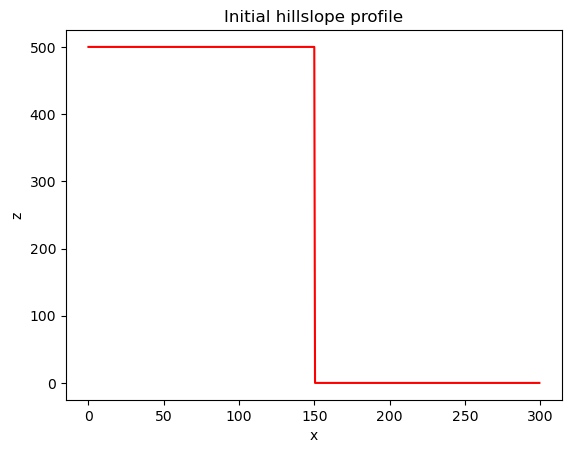

In [10]:
plt.figure()
plt.plot(x, z, "r")
plt.ylabel("z")
plt.xlabel("x")
plt.title("Initial hillslope profile")
plt.show()

In [12]:
nt = 5000
dt = 0.5 * dx**2 / D
print(dt)

0.00125


In [ ]:
Loop over the time steps of the model.

In [13]:
for t in range(0, nt):
	z[1:-1] += D * dt / dx ** 2 * (z[:-2] - 2*z[1:-1] + z[2:])

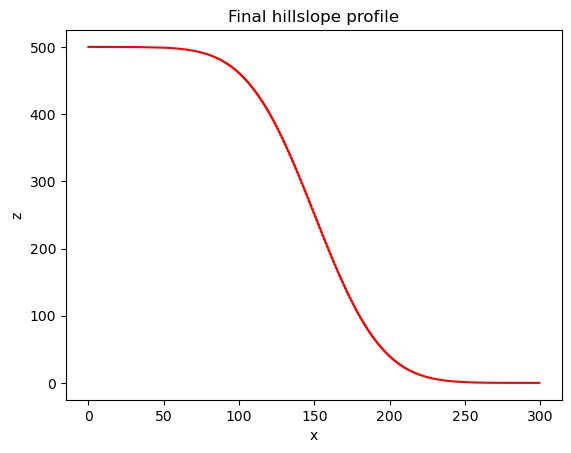

In [15]:
plt.figure()
plt.plot(x, z, "r")
plt.ylabel("z")
plt.xlabel("x")
plt.title("Final hillslope profile")
plt.show()